Train and evaluate an XGBoost model by performing hyperparameter tuning with Bayesian Optimization, analyzing feature interactions, and visualizing model performance using SHAP summary plots.

In [3]:
import numpy as np
import pandas as pd
import xgboost as xgb
import shap
import matplotlib.pyplot as plt

from skopt import BayesSearchCV
from skopt.space import Real, Integer

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix

import os
import joblib

In [9]:
save_folder = "task31_saved_files"

saved_models = "saved_models"
preprocessor = joblib.load(os.path.join(save_folder, "preprocessor.pkl"))
feature_config = joblib.load(os.path.join(save_folder, "feature_config.pkl"))
x_test = joblib.load(os.path.join(save_folder, "x_test.pkl"))
y_test = joblib.load(os.path.join(save_folder, "y_test.pkl"))
x_train = joblib.load(os.path.join(save_folder, "x_train.pkl"))
y_train = joblib.load(os.path.join(save_folder, "y_train.pkl"))

x_train_processed = preprocessor.transform(x_train)
x_test_processed = preprocessor.transform(x_test)

baseline_xgb_model = joblib.load(os.path.join(saved_models, "baseline_xgb_model.pkl"))

tuned_xgb_model = joblib.load(os.path.join(saved_models, "tuned_xgb_model.pkl"))

print("All saved files loaded successfully!")

All saved files loaded successfully!


In [11]:
print("PREPROCESSOR")
print(type(preprocessor))

print("\nBASELINE MODEL")
print(type(baseline_xgb_model))

print("\nTUNED MODEL")
print(type(tuned_xgb_model))

print("\nDATASET SHAPES")
print("X_train:", x_train.shape)
print("X_test:", x_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTARGET DISTRIBUTION")
print(y_train.value_counts())

print("\nMODEL PARAMETERS")
print(tuned_xgb_model.get_params())

print("Processed training shape:", x_train_processed.shape)
print("Processed testing shape:", x_test_processed.shape)

PREPROCESSOR
<class 'sklearn.compose._column_transformer.ColumnTransformer'>

BASELINE MODEL
<class 'xgboost.sklearn.XGBClassifier'>

TUNED MODEL
<class 'xgboost.sklearn.XGBClassifier'>

DATASET SHAPES
X_train: (18786, 15)
X_test: (4697, 15)
y_train: (18786,)
y_test: (4697,)

TARGET DISTRIBUTION
recommend_flag
1    15448
0     3338
Name: count, dtype: int64

MODEL PARAMETERS
{'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': 30, 'enable_categorical': True, 'eval_metric': 'logloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.05, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 7, 'max_leaves': None, 'min_child_weight': 1, 'missing': nan, 'monotone_constraint

In [12]:
# Transform original data using the loaded preprocessor
X_train_check = preprocessor.transform(x_train)
X_test_check = preprocessor.transform(x_test)

print("Preprocessed Training Shape:", X_train_check.shape)
print("Preprocessed Testing Shape:", X_test_check.shape)

print("\nModel Expected Features:")
print("Baseline Model:", baseline_xgb_model.n_features_in_)
print("Tuned Model:", tuned_xgb_model.n_features_in_)

print("\nPrediction Compatibility:")

print("Baseline Predictions:")
print(baseline_xgb_model.predict(X_test_check[:5]))

print("\nTuned Model Predictions:")
print(tuned_xgb_model.predict(X_test_check[:5]))

Preprocessed Training Shape: (18786, 3049)
Preprocessed Testing Shape: (4697, 3049)

Model Expected Features:
Baseline Model: 3049
Tuned Model: 3049

Prediction Compatibility:
Baseline Predictions:
[1 1 1 1 1]

Tuned Model Predictions:
[1 1 1 1 1]


Bayesian Optimization using XGBoost

In [ ]:
from skopt import BayesSearchCV
from skopt.space import Real, Integer
from sklearn.model_selection import StratifiedKFold
import xgboost as xgb

In [13]:
xgb_model = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', random_state=42, n_jobs=-1)

search_space = {
    'learning_rate': Real(0.01, 0.3, prior='log-uniform'),
    'max_depth': Integer(3, 10),
    'n_estimators': Integer(100, 500),
    'subsample': Real(0.5, 1.0),
    'colsample_bytree': Real(0.5, 1.0),
    'min_child_weight': Integer(1, 10),
    'gamma': Real(0, 5)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

bayes_search = BayesSearchCV(estimator=xgb_model, search_spaces=search_space, n_iter=25, scoring='f1', cv=cv, n_jobs=-1, verbose=1, random_state=42)   

bayes_search.fit(x_train_processed, y_train)

print("Best Parameters:")
print(bayes_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(bayes_search.best_score_, 4))

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fi

Evaluate the optimized model

In [14]:
best_bayes_model = bayes_search.best_estimator_


y_pred_bayes = best_bayes_model.predict(x_test_processed)
y_prob_bayes = best_bayes_model.predict_proba(x_test_processed)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred_bayes), 4))
print("Precision:", round(precision_score(y_test, y_pred_bayes), 4))
print("Recall:", round(recall_score(y_test, y_pred_bayes), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_bayes), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_bayes), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_bayes))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_bayes))

Accuracy: 0.9444
Precision: 0.9697
Recall: 0.9625
F1 Score: 0.9661
ROC-AUC: 0.9806

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.86      0.85       834
           1       0.97      0.96      0.97      3863

    accuracy                           0.94      4697
   macro avg       0.90      0.91      0.91      4697
weighted avg       0.95      0.94      0.94      4697


Confusion Matrix:
[[ 718  116]
 [ 145 3718]]


SHAP Analysis

Calculate SHAP values

In [15]:
x_sample = x_test_processed[:200]

# Convert sparse matrix to dense if required
if hasattr(x_sample, "toarray"):
    x_sample = x_sample.toarray()

feature_names = preprocessor.get_feature_names_out()

# Create SHAP Explainer
explainer = shap.Explainer(best_bayes_model)

shap_values = explainer(x_sample)

print("SHAP Shape:", shap_values.values.shape)
print("Feature Names:", len(feature_names))


SHAP Shape: (200, 3049)
Feature Names: 3049


SHAP Summary Plot

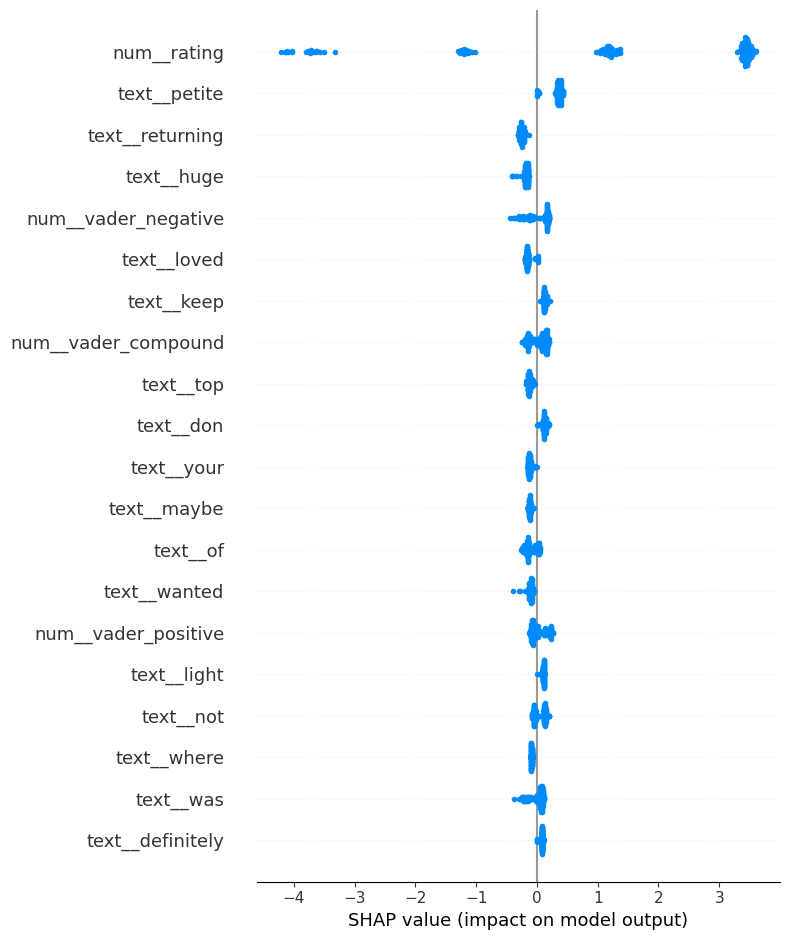

In [18]:
shap.summary_plot(shap_values.values, feature_names=feature_names, plot_type="dot", max_display=20, show=False)

Feature Interaction Analysis

Top 5 Important Features and Their Interactions
------------------------------------------------

Main Feature: num__rating
SHAP Importance: 2.65906
Potential Interaction Feature: num__customer_age


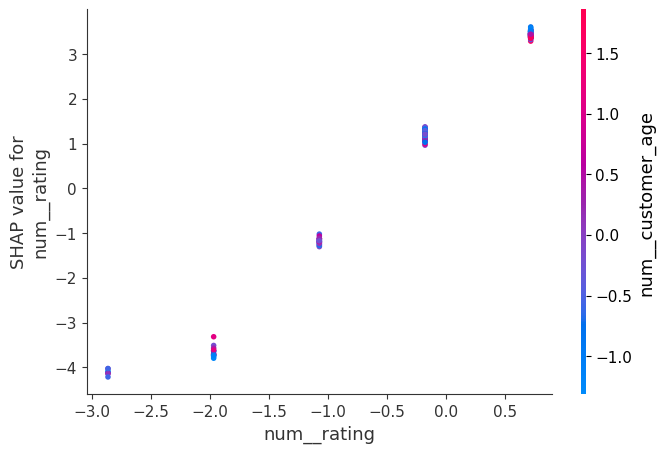


Main Feature: text__petite
SHAP Importance: 0.34578
Potential Interaction Feature: num__rating


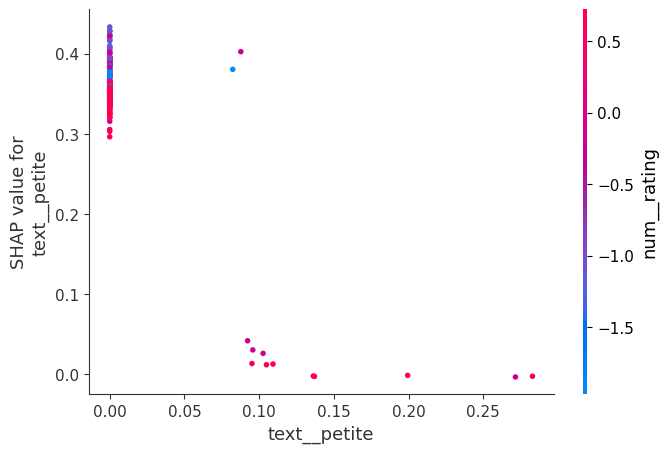


Main Feature: text__returning
SHAP Importance: 0.25022
Potential Interaction Feature: num__vader_negative


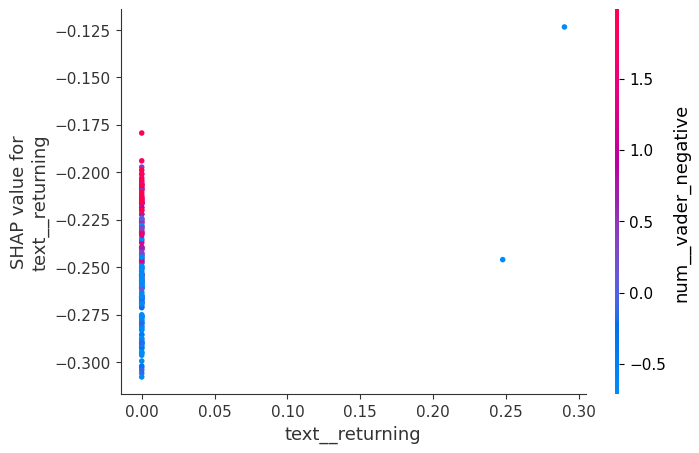


Main Feature: text__huge
SHAP Importance: 0.18039
Potential Interaction Feature: num__vader_compound


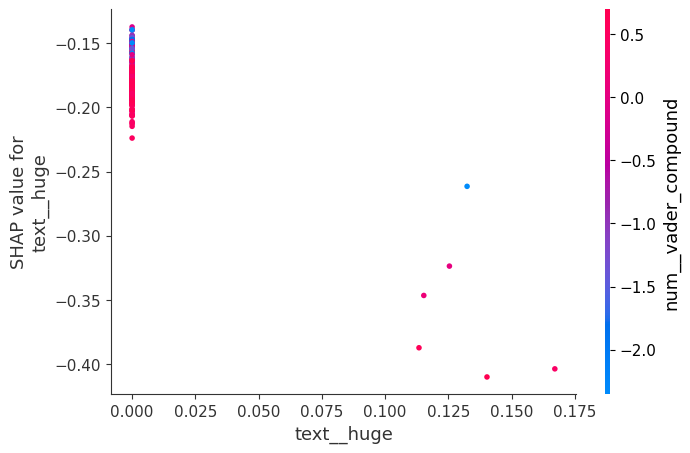


Main Feature: num__vader_negative
SHAP Importance: 0.16415
Potential Interaction Feature: num__vader_neutral


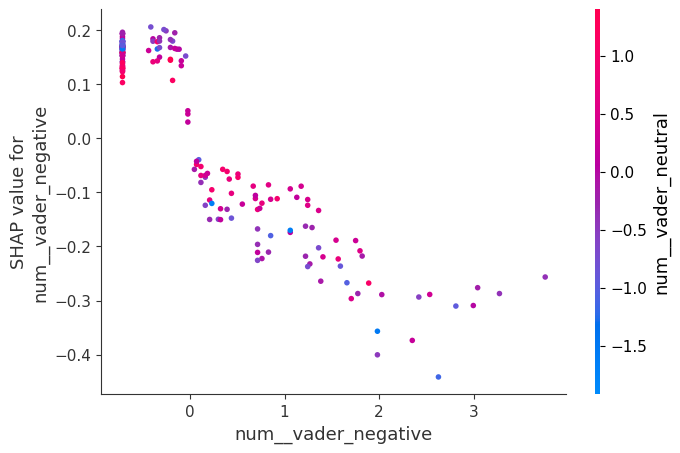

In [17]:
mean_shap = np.abs(shap_values.values).mean(axis=0)

# Identify top 5 important features
top_feature_indices = np.argsort(mean_shap)[-5:][::-1]

print("Top 5 Important Features and Their Interactions")
print("------------------------------------------------")

for idx in top_feature_indices:

    # Find approximate interaction partners
    interaction_indices = shap.utils.approximate_interactions(
        idx,
        shap_values.values,
        x_sample
    )

    # Select strongest interaction partner (excluding itself)
    interaction_idx = next(
        (int(i) for i in interaction_indices if i != idx),
        None
    )

    print("\nMain Feature:", feature_names[idx])
    print("SHAP Importance:", round(mean_shap[idx], 5))

    if interaction_idx is not None:
        print("Potential Interaction Feature:", feature_names[interaction_idx])

        shap.dependence_plot(
            idx,
            shap_values.values,
            x_sample,
            feature_names=feature_names,
            interaction_index=interaction_idx
        )



Conclusion
Successfully trained and evaluated an XGBoost classification model using Bayesian Optimization for hyperparameter tuning. The optimization process explored different combinations of learning rate, maximum tree depth, number of estimators, subsampling, column sampling, minimum child weight, and gamma. The best configuration achieved a cross-validation F1-score of 96.56%.

The optimized model was evaluated on the test dataset and achieved 94.44% accuracy, 96.97% precision, 96.25% recall, 96.61% F1-score, and 98.06% ROC-AUC, demonstrating strong classification performance.

SHAP analysis was performed to interpret the model's predictions through feature importance and summary plots. The results identified num__rating as the most influential feature, followed by text__petite, text__returning, text__huge, and num__vader_negative. Feature interaction analysis also identified potential relationships between rating and customer age, negative and neutral sentiment, and other review-text features.

Overall, this task demonstrated the application of Bayesian Optimization for efficient hyperparameter tuning and SHAP for model interpretability and feature interaction analysis.